In [1]:
# Import required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Set the main dataset folder path

dataset_path = "../data/raw/NEU-DET"

# Set the path for training images and annotations

train_images = dataset_path + "/Train/Images"
train_annotations = dataset_path + "/Train/Annotations"

# Set the path for validation images and annotations

val_images = dataset_path + "/Validation/Images"
val_annotations = dataset_path + "/Validation/Annotations"

print("Dataset paths are ready!")

Dataset paths are ready!


In [3]:
# Check whether the dataset folders are available

print("Checking dataset folders...")

if os.path.exists(train_images):
    print("Training images folder is available")
else:
    print("Training images folder is not found")

if os.path.exists(train_annotations):
    print("Training annotations folder is available")
else:
    print("Training annotations folder is not found")

if os.path.exists(val_images):
    print("Validation images folder is available")
else:
    print("Validation images folder is not found")

if os.path.exists(val_annotations):
    print("Validation annotations folder is available")
else:
    print("Validation annotations folder is not found")

Checking dataset folders...
Training images folder is available
Training annotations folder is available
Validation images folder is available
Validation annotations folder is available


In [4]:
# Get the list of training images

train_image_list = os.listdir(train_images)

# Get the list of validation images

val_image_list = os.listdir(val_images)

# Count the total number of images

print("Total Training Images:", len(train_image_list))
print("Total Validation Images:", len(val_image_list))

# Display total images in the dataset

total_images = len(train_image_list) + len(val_image_list)

print("Total Images:", total_images)

Total Training Images: 6
Total Validation Images: 6
Total Images: 12


In [5]:
# Get all training image filenames

image_names = os.listdir(train_images)

print("Image names loaded successfully!")

Image names loaded successfully!


In [6]:
# Display first 10 image filenames

print(image_names[:10])

['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [7]:
# Create an empty dictionary

class_count = {}

# Count images for each defect class

for image in image_names:

    class_name = image.split("_")[0]

    if class_name in class_count:
        class_count[class_name] += 1
    else:
        class_count[class_name] = 1

# Display the image count of each class

print("Defect Class Image Count:")

for class_name, count in class_count.items():
    print(class_name, ":", count)

Defect Class Image Count:
crazing : 1
inclusion : 1
patches : 1
pitted : 1
rolled-in : 1
scratches : 1


In [8]:
# Display some image filenames

for image in image_names[:20]:
    print(image)

crazing
inclusion
patches
pitted_surface
rolled-in_scale
scratches


In [9]:
# Count images in each defect folder

class_count = {}

for class_name in os.listdir(train_images):

    class_path = os.path.join(train_images, class_name)

    if os.path.isdir(class_path):

        images = os.listdir(class_path)

        class_count[class_name] = len(images)

# Display class names and image counts

print("Defect Class Image Count:")

for class_name, count in class_count.items():
    print(class_name, ":", count)

Defect Class Image Count:
crazing : 240
inclusion : 240
patches : 240
pitted_surface : 240
rolled-in_scale : 240
scratches : 240


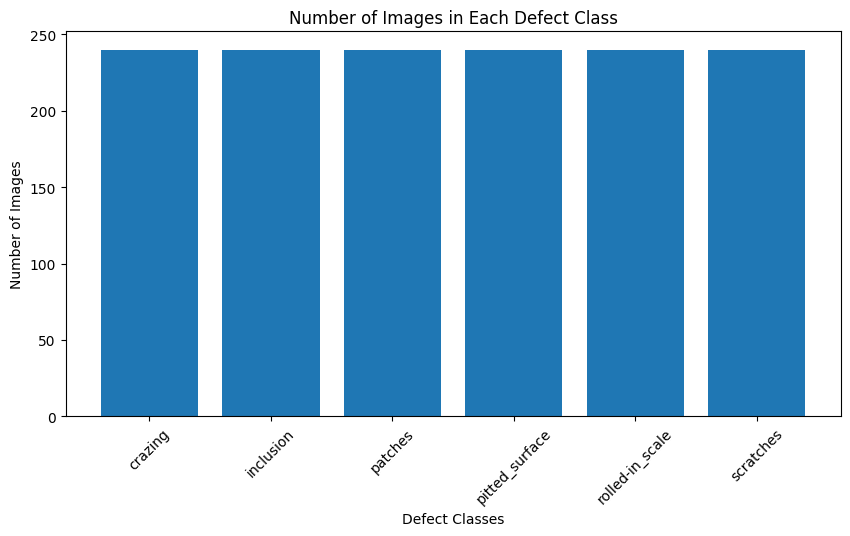

In [10]:
# Create a bar chart for defect classes

classes = list(class_count.keys())
counts = list(class_count.values())

plt.figure(figsize=(10, 5))

plt.bar(classes, counts)

plt.title("Number of Images in Each Defect Class")
plt.xlabel("Defect Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.show()

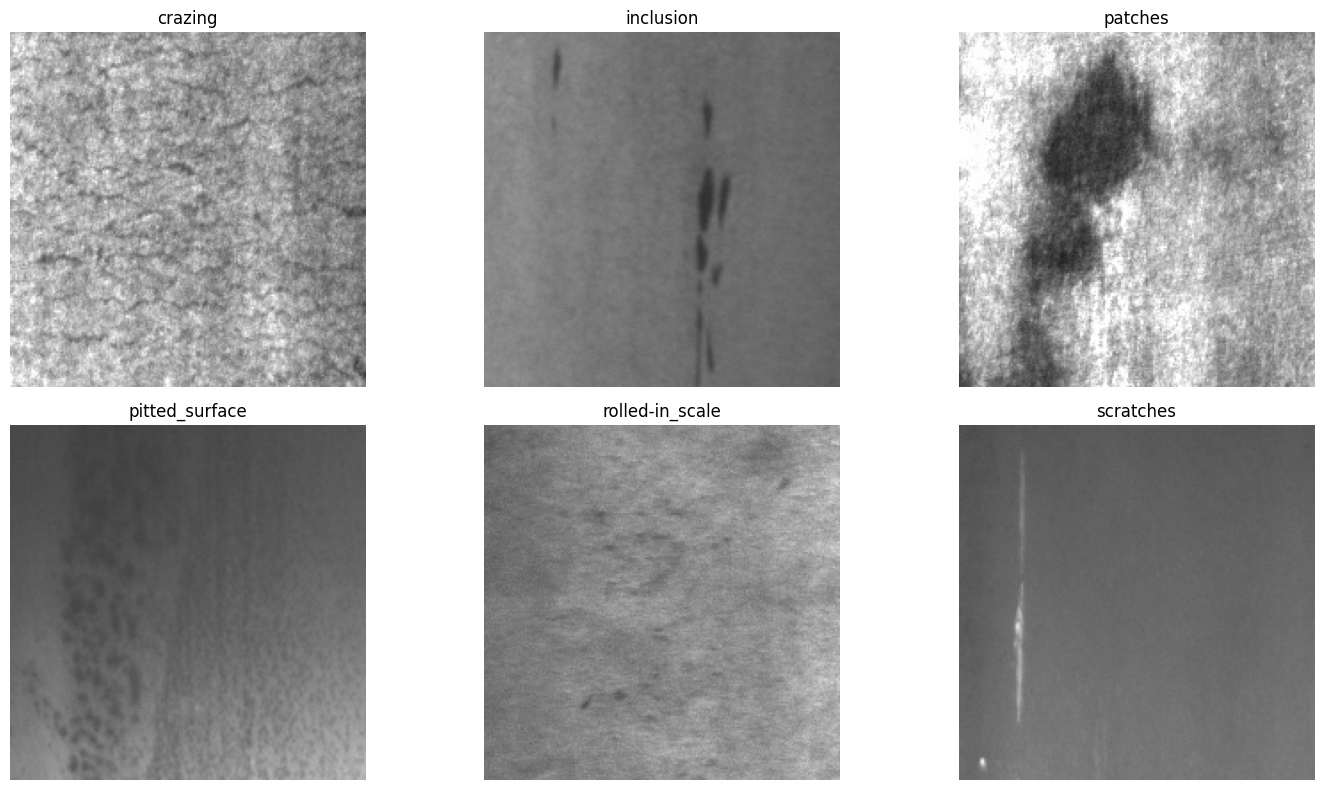

In [11]:
# Display one image from each defect class

plt.figure(figsize=(15, 8))

for i, class_name in enumerate(class_count.keys()):

    class_path = os.path.join(train_images, class_name)

    image_name = os.listdir(class_path)[0]

    image_path = os.path.join(class_path, image_name)

    img = Image.open(image_path)

    plt.subplot(2, 3, i + 1)

    plt.imshow(img, cmap="gray")

    plt.title(class_name)

    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Import XML library

import xml.etree.ElementTree as ET

# Get XML annotation files

annotation_files = os.listdir(train_annotations)

# Select the first XML file

xml_path = os.path.join(train_annotations, annotation_files[0])

# Read the XML file

tree = ET.parse(xml_path)

# Get the root element

root = tree.getroot()

# Display XML information

print("XML File Name:", annotation_files[0])
print("Image Name:", root.find("filename").text)
print("Image Width:", root.find("size/width").text)
print("Image Height:", root.find("size/height").text)

XML File Name: crazing_1.xml
Image Name: crazing_1.jpg
Image Width: 200
Image Height: 200


In [13]:
# Get defect information from XML

object_info = root.find("object")

# Get defect class name

defect_name = object_info.find("name").text

# Get bounding box information

box = object_info.find("bndbox")

xmin = box.find("xmin").text
ymin = box.find("ymin").text
xmax = box.find("xmax").text
ymax = box.find("ymax").text

# Display defect information

print("Defect Name:", defect_name)
print("X Minimum:", xmin)
print("Y Minimum:", ymin)
print("X Maximum:", xmax)
print("Y Maximum:", ymax)

Defect Name: crazing
X Minimum: 2
Y Minimum: 2
X Maximum: 193
Y Maximum: 194


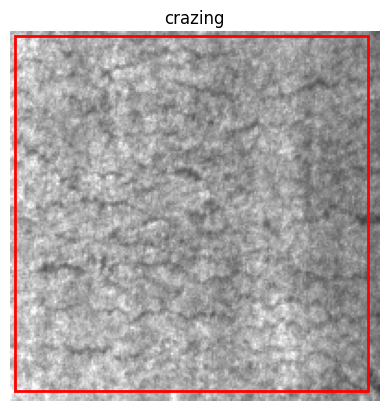

In [14]:
# Import Rectangle to draw a box

import matplotlib.patches as patches

# Open the image mentioned in XML

image_path = os.path.join(train_images, defect_name, root.find("filename").text)

img = Image.open(image_path)

# Convert coordinates into integers

xmin = int(xmin)
ymin = int(ymin)
xmax = int(xmax)
ymax = int(ymax)

# Display the image

fig, ax = plt.subplots()

ax.imshow(img, cmap="gray")

# Draw bounding box

rectangle = patches.Rectangle(
    (xmin, ymin),
    xmax - xmin,
    ymax - ymin,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rectangle)

plt.title(defect_name)
plt.axis("off")
plt.show()

In [15]:
# Display dataset summary

print("NEU-DET Dataset Summary")

print("------------------------")

print("Total Defect Classes:", len(class_count))

print("Training Images:", sum(class_count.values()))

print("Validation Images:", len(val_image_list))

print("Defect Classes:")

for class_name in class_count:
    print("-", class_name)

NEU-DET Dataset Summary
------------------------
Total Defect Classes: 6
Training Images: 1440
Validation Images: 6
Defect Classes:
- crazing
- inclusion
- patches
- pitted_surface
- rolled-in_scale
- scratches


In [ ]:
!python -m streamlit run "../app/main.py"